# Tahap 5 - Training Model Advanced

##Advanced



In [ ]:
!pip -q install scikit-learn joblib

In [ ]:
#@title Install Library
import json
import time
import joblib
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Library berhasil dimuat.")

Library berhasil dimuat.


In [ ]:
#@title Konfigurasi eksperimen Random Forest
RANDOM_STATE = 42

CLASS_COLUMNS = [
    "overripe",
    "ripe",
    "underripe",
    "unripe"
]

# Lokasi fitur hasil notebook SVM
FEATURE_PATH = Path(
    "/content/model_baseline_svm/features/svm_features.csv"
)

# Direktori hasil Random Forest
OUTPUT_DIR = Path("/content/model_advanced_rf")
MODEL_DIR = OUTPUT_DIR / "models"
RESULT_DIR = OUTPUT_DIR / "results"

for folder in [MODEL_DIR, RESULT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Konfigurasi berhasil.")
print("Feature file:", FEATURE_PATH)
print("Output:", OUTPUT_DIR)

Konfigurasi berhasil.
Feature file: /content/model_baseline_svm/features/svm_features.csv
Output: /content/model_advanced_rf


In [ ]:
#@title Memuat hasil ekstraksi fitur
if not FEATURE_PATH.exists():
    raise FileNotFoundError(
        "File fitur tidak ditemukan. Pastikan notebook SVM "
        "sudah dijalankan dan svm_features.csv tersedia."
    )

df_features = pd.read_csv(FEATURE_PATH)

print("Jumlah seluruh data:", len(df_features))
print("Jumlah kolom:", len(df_features.columns))

display(df_features.head())

Jumlah seluruh data: 5790
Jumlah kolom: 84


,filename,split,label,image_path,hsv_h_0,hsv_h_1,hsv_h_2,hsv_h_3,hsv_h_4,hsv_h_5,...,glcm_correlation_d2_a2,glcm_correlation_d2_a3,glcm_ASM_d1_a0,glcm_ASM_d1_a1,glcm_ASM_d1_a2,glcm_ASM_d1_a3,glcm_ASM_d2_a0,glcm_ASM_d2_a1,glcm_ASM_d2_a2,glcm_ASM_d2_a3
0,overripe-331-_jpg.rf.c1763e711e9ef04733e50d111...,train,overripe,/content/oil_palm_dataset/train/overripe-331-_...,0.738159,0.094971,0.034546,0.019897,0.005676,0.009216,...,0.734668,0.812341,0.189758,0.178597,0.179064,0.178557,0.188334,0.178597,0.167661,0.178557
1,ripe-142-_jpg.rf.08f25705cee08800d054de12cc10b...,train,ripe,/content/oil_palm_dataset/train/ripe-142-_jpg....,0.293762,0.049255,0.003479,0.000549,0.000000,0.001709,...,0.371619,0.555077,0.028918,0.022756,0.027216,0.023077,0.021201,0.022756,0.020567,0.023077
2,ripe-320-_jpg.rf.128360b737a545d72dcf2756f5415...,train,ripe,/content/oil_palm_dataset/train/ripe-320-_jpg....,0.591675,0.175781,0.013916,0.003967,0.004028,0.007080,...,0.831346,0.852287,0.137054,0.134916,0.145763,0.134969,0.127364,0.134916,0.141482,0.134969
3,underripe-166-_png.rf.11d7ca27b9d442bf1a518e05...,train,underripe,/content/oil_palm_dataset/train/underripe-166-...,0.244202,0.223450,0.067383,0.020142,0.005310,0.006042,...,0.509616,0.739207,0.020300,0.013368,0.016166,0.014186,0.013059,0.013368,0.010446,0.014186
4,ripe-33-_jpg.rf.baa6b566a7a95572efd4b721590533...,train,ripe,/content/oil_palm_dataset/train/ripe-33-_jpg.r...,0.258911,0.398926,0.091675,0.026123,0.008179,0.011902,...,0.303827,0.453347,0.020587,0.017248,0.020927,0.017945,0.016512,0.017248,0.016835,0.017945


In [ ]:
#@title Identifikasi Kolom
metadata_columns = [
    "filename",
    "split",
    "label",
    "image_path"
]

feature_names = [
    col for col in df_features.columns
    if col not in metadata_columns
]

assert len(feature_names) == 80, (
    f"Seharusnya terdapat 80 fitur, ditemukan {len(feature_names)}."
)

assert df_features[metadata_columns].notna().all().all()
assert df_features[feature_names].notna().all().all()

assert np.isfinite(
    df_features[feature_names].to_numpy(dtype=np.float32)
).all()

print("Jumlah fitur:", len(feature_names))
print("Pemeriksaan data berhasil.")

Jumlah fitur: 80
Pemeriksaan data berhasil.


In [ ]:
#@title Memisahkan Training, Validation, Testing
train_mask = df_features["split"].eq("train")
valid_mask = df_features["split"].eq("valid")
test_mask = df_features["split"].eq("test")

X_train = df_features.loc[
    train_mask, feature_names
].to_numpy(dtype=np.float32)

y_train = df_features.loc[
    train_mask, "label"
].to_numpy()

X_valid = df_features.loc[
    valid_mask, feature_names
].to_numpy(dtype=np.float32)

y_valid = df_features.loc[
    valid_mask, "label"
].to_numpy()

X_test = df_features.loc[
    test_mask, feature_names
].to_numpy(dtype=np.float32)

y_test = df_features.loc[
    test_mask, "label"
].to_numpy()

print("Training  :", X_train.shape, y_train.shape)
print("Validation:", X_valid.shape, y_valid.shape)
print("Testing   :", X_test.shape, y_test.shape)

Training  : (5074, 80) (5074,)
Validation: (474, 80) (474,)
Testing   : (242, 80) (242,)


In [ ]:
#@title Jumlah Distribusi Kelas
split_summary = (
    df_features.groupby(["split", "label"])
    .size()
    .unstack(fill_value=0)
)

display(split_summary)

assert len(X_train) == 5074
assert len(X_valid) == 474
assert len(X_test) == 242

assert set(np.unique(y_train)) == set(CLASS_COLUMNS)
assert set(np.unique(y_valid)) == set(CLASS_COLUMNS)

print("Pembagian dataset selesai.")

label,overripe,ripe,underripe,unripe
split,,,,
test,78,61,55,48
train,1392,1431,1237,1014
valid,136,128,118,92


Pembagian dataset selesai.


In [ ]:
#@title Training Random Forest dengan parameter awal
model_rf_initial = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

start_time = time.time()

model_rf_initial.fit(X_train, y_train)

initial_training_time = time.time() - start_time

print("Training Random Forest awal selesai.")
print(
    "Waktu training:",
    round(initial_training_time, 2),
    "detik"
)

Training Random Forest awal selesai.
Waktu training: 10.76 detik


In [ ]:
#@title Evaluasi Random Forest
y_valid_pred_initial = model_rf_initial.predict(X_valid)


def calculate_metrics(y_true, y_pred, model_name):
    return {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "recall_macro": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "f1_macro": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "f1_weighted": f1_score(
            y_true, y_pred,
            average="weighted",
            zero_division=0
        )
    }


metrics_initial = calculate_metrics(
    y_valid,
    y_valid_pred_initial,
    "Random Forest - Initial"
)

metrics_initial["training_time_seconds"] = initial_training_time

display(
    pd.DataFrame([metrics_initial]).round(4)
)

print(
    classification_report(
        y_valid,
        y_valid_pred_initial,
        labels=CLASS_COLUMNS,
        target_names=CLASS_COLUMNS,
        zero_division=0
    )
)

,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,training_time_seconds
0,Random Forest - Initial,0.8354,0.8329,0.8294,0.8296,0.8336,10.7645


              precision    recall  f1-score   support

    overripe       0.85      0.95      0.90       136
        ripe       0.85      0.75      0.80       128
   underripe       0.83      0.85      0.84       118
      unripe       0.81      0.77      0.79        92

    accuracy                           0.84       474
   macro avg       0.83      0.83      0.83       474
weighted avg       0.84      0.84      0.83       474



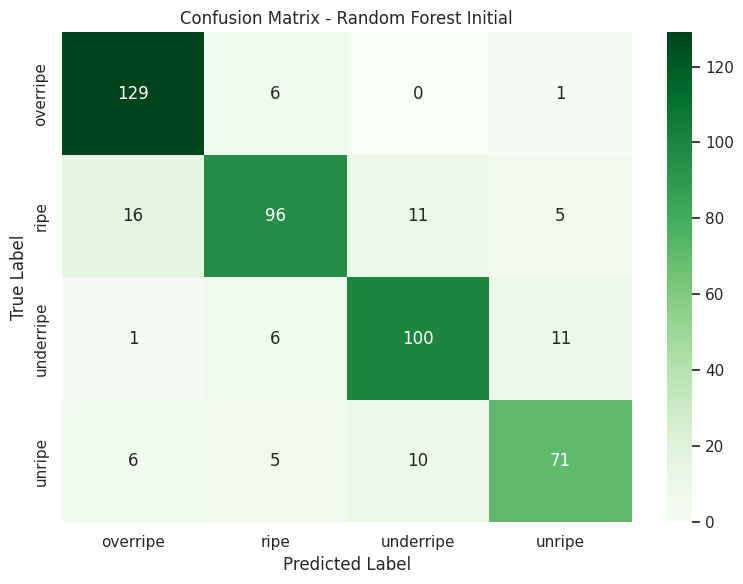

In [ ]:
#@title Evaluation Matrix
cm_initial = confusion_matrix(
    y_valid,
    y_valid_pred_initial,
    labels=CLASS_COLUMNS
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_initial,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=CLASS_COLUMNS,
    yticklabels=CLASS_COLUMNS
)

plt.title("Confusion Matrix - Random Forest Initial")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [ ]:
#@title Hyperparameter Tunning
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 20, 30],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt"]
}

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

rf_for_search = RandomForestClassifier(
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=1
)

grid_search = GridSearchCV(
    estimator=rf_for_search,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    refit=True,
    return_train_score=True
)

start_time = time.time()

grid_search.fit(X_train, y_train)

tuning_time = time.time() - start_time

print("Grid Search selesai.")
print("Waktu tuning:", round(tuning_time, 2), "detik")
print("Best parameters:")
print(grid_search.best_params_)
print("Best CV F1 Macro:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Grid Search selesai.
Waktu tuning: 832.15 detik
Best parameters:
{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best CV F1 Macro: 0.7892


In [ ]:
#@title Hasil seluruh kombinasi
cv_results = pd.DataFrame(grid_search.cv_results_)

cv_summary = cv_results[
    [
        "param_n_estimators",
        "param_max_depth",
        "param_min_samples_split",
        "param_min_samples_leaf",
        "mean_train_score",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].sort_values("rank_test_score")

display(cv_summary.head(10))

,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf,mean_train_score,mean_test_score,std_test_score,rank_test_score
9,200,20,2,1,1.000000,0.789210,0.006565,1
3,200,None,5,1,1.000000,0.786645,0.012269,2
1,200,None,2,1,1.000000,0.786370,0.008853,3
17,200,30,2,1,1.000000,0.786370,0.008853,3
19,200,30,5,1,1.000000,0.786327,0.012076,5
11,200,20,5,1,1.000000,0.785991,0.005746,6
8,100,20,2,1,1.000000,0.785982,0.010635,7
0,100,None,2,1,1.000000,0.781479,0.008768,8
16,100,30,2,1,1.000000,0.781479,0.008768,8
23,200,30,5,2,0.999231,0.781444,0.004708,10


In [ ]:
#@title Simpan hasil tunning
cv_summary.to_csv(
    RESULT_DIR / "grid_search_results.csv",
    index=False
)

print("Hasil Grid Search berhasil disimpan.")

Hasil Grid Search berhasil disimpan.


In [ ]:
#@title Evaluasi setelah tunning
model_rf_best = grid_search.best_estimator_

y_valid_pred_tuned = model_rf_best.predict(X_valid)

metrics_tuned = calculate_metrics(
    y_valid,
    y_valid_pred_tuned,
    "Random Forest - Tuned"
)

metrics_tuned["training_time_seconds"] = np.nan

display(
    pd.DataFrame([metrics_tuned]).round(4)
)

print(
    classification_report(
        y_valid,
        y_valid_pred_tuned,
        labels=CLASS_COLUMNS,
        target_names=CLASS_COLUMNS,
        zero_division=0
    )
)

,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,training_time_seconds
0,Random Forest - Tuned,0.8312,0.8268,0.8247,0.825,0.83,NaN


              precision    recall  f1-score   support

    overripe       0.86      0.93      0.89       136
        ripe       0.83      0.77      0.80       128
   underripe       0.83      0.83      0.83       118
      unripe       0.79      0.76      0.77        92

    accuracy                           0.83       474
   macro avg       0.83      0.82      0.82       474
weighted avg       0.83      0.83      0.83       474



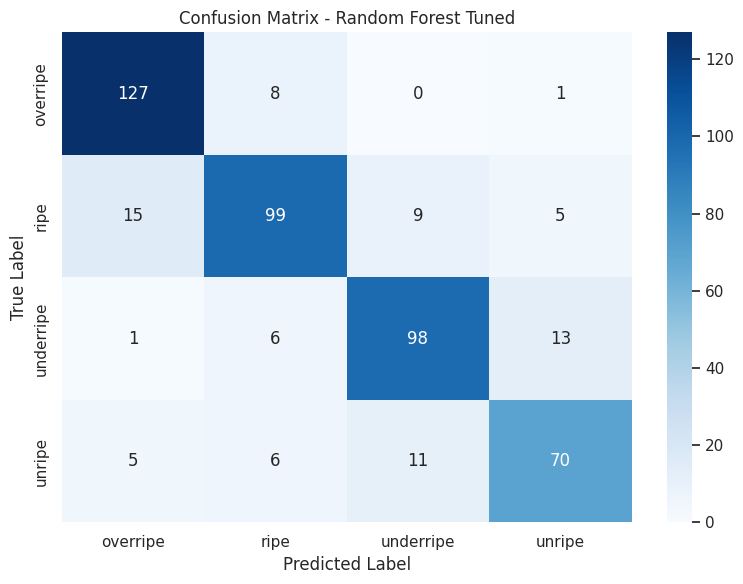

In [ ]:
#@title Confussion Matrix setelah tunning
cm_tuned = confusion_matrix(
    y_valid,
    y_valid_pred_tuned,
    labels=CLASS_COLUMNS
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_COLUMNS,
    yticklabels=CLASS_COLUMNS
)

plt.title("Confusion Matrix - Random Forest Tuned")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [ ]:
#@title Perbandingan sebelum dan setelah tunning
comparison_tuning = pd.DataFrame([
    {
        "Experiment": "Before Tuning",
        **metrics_initial
    },
    {
        "Experiment": "After Tuning",
        **metrics_tuned
    }
])

display(
    comparison_tuning.round(4)
)

,Experiment,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,training_time_seconds
0,Before Tuning,Random Forest - Initial,0.8354,0.8329,0.8294,0.8296,0.8336,10.7645
1,After Tuning,Random Forest - Tuned,0.8312,0.8268,0.8247,0.8250,0.8300,NaN


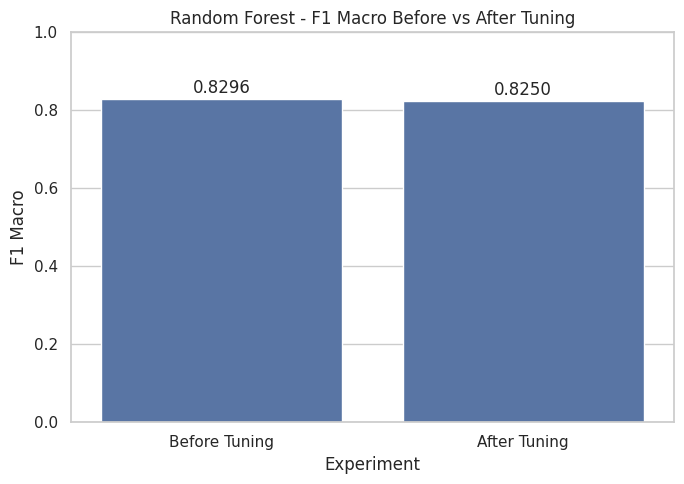

In [ ]:
#@title Visualisasi Perbandingan F1-Score
plt.figure(figsize=(7, 5))

sns.barplot(
    data=comparison_tuning,
    x="Experiment",
    y="f1_macro"
)

plt.title("Random Forest - F1 Macro Before vs After Tuning")
plt.xlabel("Experiment")
plt.ylabel("F1 Macro")
plt.ylim(0, 1)

for i, value in enumerate(comparison_tuning["f1_macro"]):
    plt.text(i, value + 0.015, f"{value:.4f}", ha="center")

plt.tight_layout()
plt.show()

In [ ]:
#@title Analisis Feature Importance
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": model_rf_best.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
).reset_index(drop=True)

display(importance_df.head(20))

,feature,importance
0,hsv_h_15,0.059333
1,hsv_h_14,0.039327
2,hsv_h_13,0.032335
3,hsv_h_12,0.031116
4,hsv_h_3,0.025775
5,hsv_h_4,0.024410
6,hsv_h_11,0.022685
7,hsv_s_5,0.020792
8,hsv_h_0,0.020742
9,hsv_v_4,0.020092


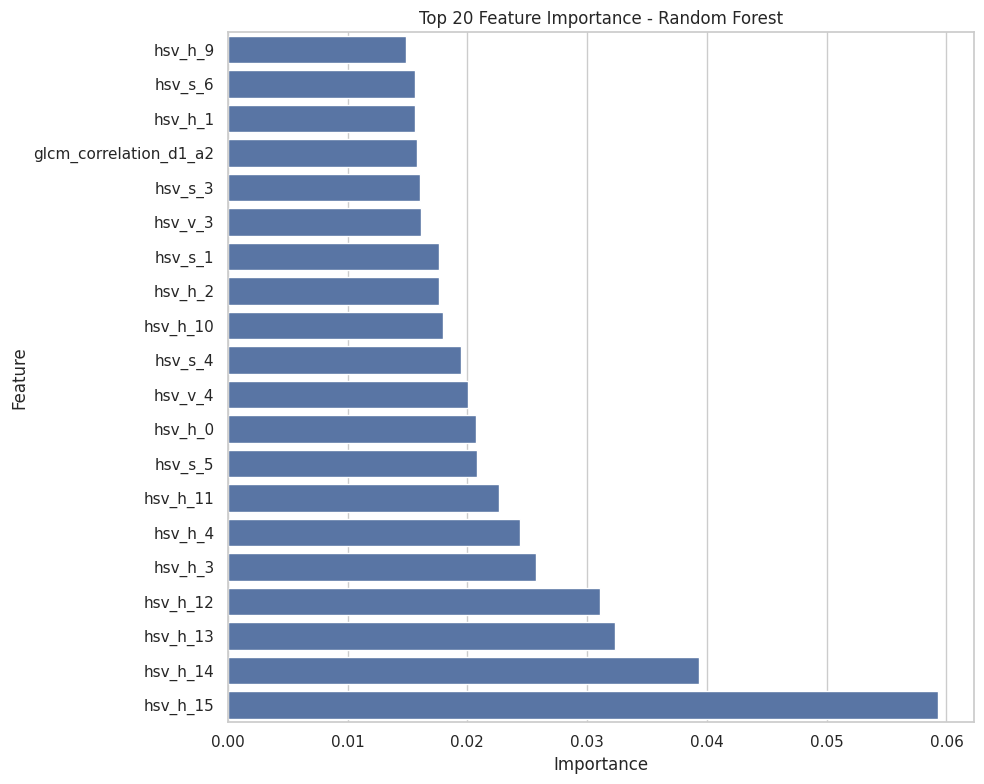

In [ ]:
#@title Visualisasi 20 terpenting
top_features = importance_df.head(20).sort_values(
    "importance",
    ascending=True
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="importance",
    y="feature"
)

plt.title("Top 20 Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [ ]:
#@title Kelompok berdasarkan jenis fitur
def get_feature_group(feature):
    if feature.startswith("hsv_"):
        return "HSV"
    elif feature.startswith("glcm_"):
        return "GLCM"
    return "Other"


importance_df["feature_group"] = (
    importance_df["feature"].apply(get_feature_group)
)

group_importance = (
    importance_df.groupby("feature_group")["importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(group_importance)

,feature_group,importance
0,HSV,0.596597
1,GLCM,0.403403


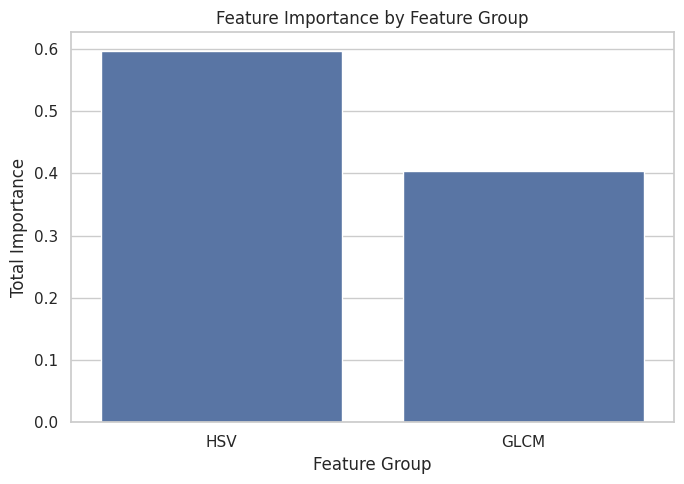

In [ ]:
#@title Visualisasi kontribusi kelompok fitur
plt.figure(figsize=(7, 5))

sns.barplot(
    data=group_importance,
    x="feature_group",
    y="importance"
)

plt.title("Feature Importance by Feature Group")
plt.xlabel("Feature Group")
plt.ylabel("Total Importance")
plt.tight_layout()
plt.show()

In [ ]:
#@title Kontrol dan diagnosis overfitting
y_train_pred = model_rf_best.predict(X_train)
y_valid_pred = model_rf_best.predict(X_valid)

overfit_metrics = pd.DataFrame([
    {
        "Dataset": "Training",
        "Accuracy": accuracy_score(y_train, y_train_pred),
        "F1 Macro": f1_score(
            y_train, y_train_pred,
            average="macro",
            zero_division=0
        )
    },
    {
        "Dataset": "Validation",
        "Accuracy": accuracy_score(y_valid, y_valid_pred),
        "F1 Macro": f1_score(
            y_valid, y_valid_pred,
            average="macro",
            zero_division=0
        )
    }
])

display(overfit_metrics.round(4))

,Dataset,Accuracy,F1 Macro
0,Training,1.0000,1.000
1,Validation,0.8312,0.825


In [ ]:
#@title Hitung selisih performa
accuracy_gap = (
    overfit_metrics.loc[0, "Accuracy"]
    - overfit_metrics.loc[1, "Accuracy"]
)

f1_gap = (
    overfit_metrics.loc[0, "F1 Macro"]
    - overfit_metrics.loc[1, "F1 Macro"]
)

print("Accuracy gap:", round(accuracy_gap, 4))
print("F1 Macro gap:", round(f1_gap, 4))

Accuracy gap: 0.1688
F1 Macro gap: 0.175


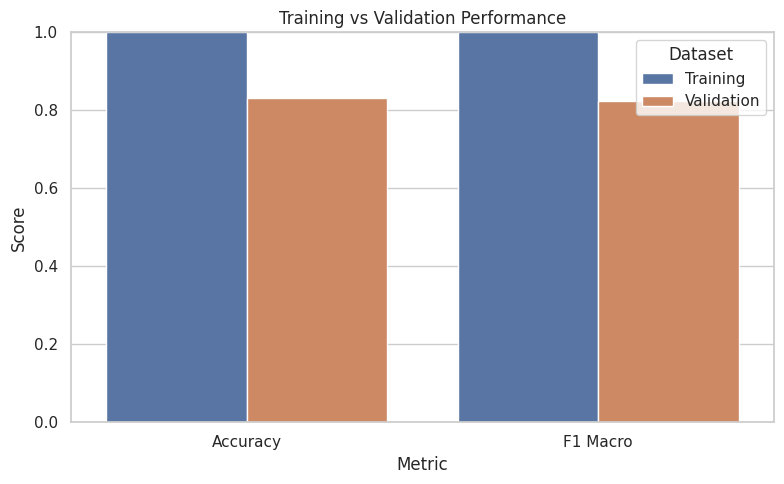

In [ ]:
#@title Visualisasi
overfit_plot = overfit_metrics.melt(
    id_vars="Dataset",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=overfit_plot,
    x="Metric",
    y="Score",
    hue="Dataset"
)

plt.title("Training vs Validation Performance")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [ ]:
#@title Perbandingan SVM & Random Forest
SVM_METRICS_PATH = Path(
    "/content/model_baseline_svm/results/validation_metrics.json"
)

if not SVM_METRICS_PATH.exists():
    raise FileNotFoundError(
        "File metrik SVM tidak ditemukan. "
        "Pastikan hasil eksperimen baseline sudah disimpan."
    )

with open(SVM_METRICS_PATH, "r") as file:
    svm_metrics = json.load(file)

comparison_models = pd.DataFrame([
    {
        "Model": "SVM Baseline",
        "Accuracy": svm_metrics["accuracy"],
        "Precision Macro": svm_metrics["precision_macro"],
        "Recall Macro": svm_metrics["recall_macro"],
        "F1 Macro": svm_metrics["f1_macro"]
    },
    {
        "Model": "Random Forest Initial",
        "Accuracy": metrics_initial["accuracy"],
        "Precision Macro": metrics_initial["precision_macro"],
        "Recall Macro": metrics_initial["recall_macro"],
        "F1 Macro": metrics_initial["f1_macro"]
    },
    {
        "Model": "Random Forest Tuned",
        "Accuracy": metrics_tuned["accuracy"],
        "Precision Macro": metrics_tuned["precision_macro"],
        "Recall Macro": metrics_tuned["recall_macro"],
        "F1 Macro": metrics_tuned["f1_macro"]
    }
])

display(comparison_models.round(4))

,Model,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,SVM Baseline,0.7595,0.7652,0.7644,0.7639
1,Random Forest Initial,0.8354,0.8329,0.8294,0.8296
2,Random Forest Tuned,0.8312,0.8268,0.8247,0.8250


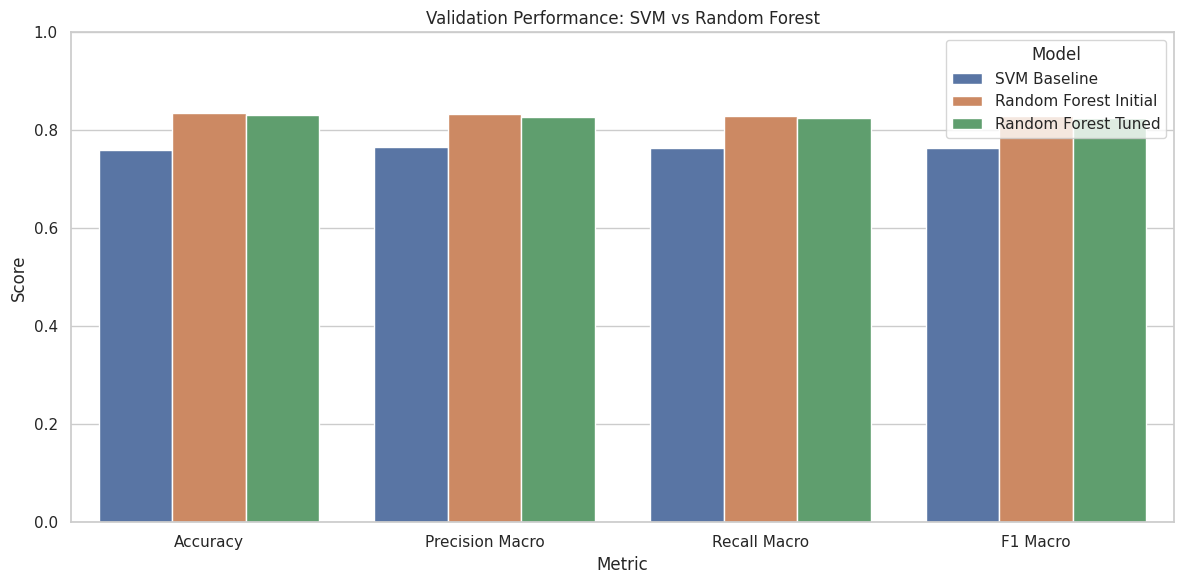

In [ ]:
#@title Visualisasi
comparison_plot = comparison_models.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_plot,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Validation Performance: SVM vs Random Forest")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [ ]:
#@title Menyimpan model hasil eksperimen
# Simpan model awal
joblib.dump(
    model_rf_initial,
    MODEL_DIR / "random_forest_initial.joblib"
)

# Simpan model terbaik
joblib.dump(
    model_rf_best,
    MODEL_DIR / "random_forest_best.joblib"
)

# Simpan parameter terbaik
with open(
    RESULT_DIR / "best_parameters.json",
    "w"
) as file:
    json.dump(grid_search.best_params_, file, indent=4)

# Simpan hasil evaluasi
results_rf = {
    "initial": metrics_initial,
    "tuned": metrics_tuned,
    "best_cv_f1_macro": float(grid_search.best_score_),
    "tuning_time_seconds": tuning_time,
    "best_parameters": grid_search.best_params_
}

with open(
    RESULT_DIR / "validation_metrics.json",
    "w"
) as file:
    json.dump(results_rf, file, indent=4)

# Simpan feature importance
importance_df.to_csv(
    RESULT_DIR / "feature_importance.csv",
    index=False
)

# Simpan prediksi validation
df_validation_result = pd.DataFrame({
    "filename": df_features.loc[valid_mask, "filename"].values,
    "actual_label": y_valid,
    "predicted_initial": y_valid_pred_initial,
    "predicted_tuned": y_valid_pred_tuned
})

df_validation_result.to_csv(
    RESULT_DIR / "validation_predictions.csv",
    index=False
)

# Simpan perbandingan model
comparison_models.to_csv(
    RESULT_DIR / "model_comparison.csv",
    index=False
)

print("Seluruh model dan hasil eksperimen berhasil disimpan.")

Seluruh model dan hasil eksperimen berhasil disimpan.
